# DayTracker – starter analysis

1. In the app: **Settings → Data → Export all data**, save the `.zip` (Files / iCloud Drive / email).
2. Put it in `analysis/data/` (ignored by git – your data never gets committed).
3. Run all cells. `dt.load()` picks the newest export.

Days run 04:00–04:00 (D14), so late-night entries count for the evening before.

In [1]:
import daytracker as dt
import matplotlib.pyplot as plt

ex = dt.load()  # or dt.load('data/DayTracker-2026-11-10-2130.zip')
print(f"{ex.source.name}: {len(ex.entries)} entries, "
      f"{ex.entries['day'].min():%d %b} – {ex.entries['day'].max():%d %b}")
ex.entries.tail()

DayTracker-2026-11-03-2132.zip: 22 entries, 03 Nov – 03 Nov


,entry_id,tracker_id,tracker_name,kind,value,unit,occurred_at,logged_at,time_zone,day,source,session_id,scheduled_for,note,occurred_local,occurred_utc,scheduled_local,hour,tracker
17,32250513-F59C-46A7-928D-B9B0BFEF5AA8,C302BA2E-F48E-48FF-A42B-368C1B2D52B9,Medicine1,dose,1.0,,2026-11-03T21:01:09+01:00,2026-11-03T21:01:09+01:00,Europe/Copenhagen,2026-11-03,notificationAction,,2026-11-03T21:01:00+01:00,,2026-11-03 21:01:09,2026-11-03 20:01:09+00:00,2026-11-03 21:01:00,21.016667,Medicine1
18,523B3CA9-18B3-45D9-BCAD-BA45E62BB7AB,C302BA2E-F48E-48FF-A42B-368C1B2D52B9,Medicine1,dose,1.0,,2026-11-03T21:13:07+01:00,2026-11-03T21:13:07+01:00,Europe/Copenhagen,2026-11-03,checkIn,3B16BC89-9702-4E67-8A5B-504898964750,,,2026-11-03 21:13:07,2026-11-03 20:13:07+00:00,NaT,21.216667,Medicine1
19,95420EC0-55D7-432F-A7F7-F8AAD7B0BDDA,733E6469-59E4-457D-A427-466B4254CDD5,Mood,scale,7.0,,2026-11-03T21:13:09+01:00,2026-11-03T21:13:09+01:00,Europe/Copenhagen,2026-11-03,checkIn,3B16BC89-9702-4E67-8A5B-504898964750,,,2026-11-03 21:13:09,2026-11-03 20:13:09+00:00,NaT,21.216667,Mood
20,8810D55A-1D87-4DDF-9E28-1A2C5D961FE9,151A4697-F9A3-4F1D-9CA3-9A49BE7209BF,Energy,scale,8.0,,2026-11-03T21:13:11+01:00,2026-11-03T21:13:11+01:00,Europe/Copenhagen,2026-11-03,checkIn,3B16BC89-9702-4E67-8A5B-504898964750,,,2026-11-03 21:13:11,2026-11-03 20:13:11+00:00,NaT,21.216667,Energy
21,34F12361-4361-446A-9AB4-BE77E0AE13E6,676A9D58-5E9D-4E9D-B56A-4ED17B16F14F,Focus,scale,3.0,,2026-11-03T21:13:12+01:00,2026-11-03T21:13:12+01:00,Europe/Copenhagen,2026-11-03,checkIn,3B16BC89-9702-4E67-8A5B-504898964750,,,2026-11-03 21:13:12,2026-11-03 20:13:12+00:00,NaT,21.216667,Focus


## Day by day
Counters are daily totals, medicines are doses taken, ratings are the day's average.

In [2]:
daily = dt.daily(ex)
daily.tail(14).round(1)

,Water,Coffee,Mood,Energy,Focus,Medicine1
day,,,,,,
2026-11-03,3.0,3.0,7.0,6.0,5.2,3.0


C:\Users\esben\dev\daytracker\.venv\Lib\site-packages\pandas\plotting\_matplotlib\core.py:1680: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  ax.set_xlim(left, right)


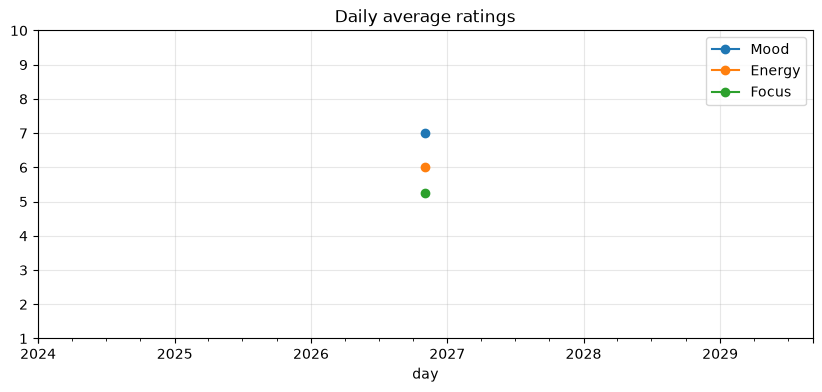

In [3]:
ratings = [c for c in daily.columns if c in set(ex.trackers.loc[ex.trackers['kind'] == 'scale', 'name'])]
ax = daily[ratings].plot(marker='o', figsize=(10, 4), ylim=(1, 10), title='Daily average ratings')
ax.grid(alpha=0.3)

## Ratings by time of day

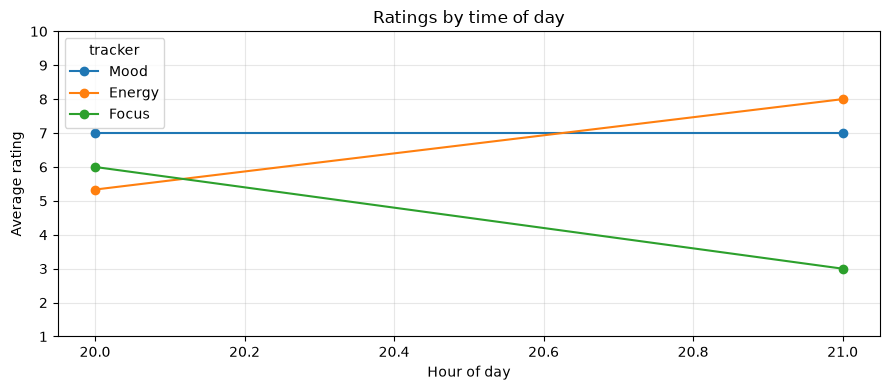

In [4]:
dt.plot_by_hour(ex);

## Weekdays

In [5]:
dt.by_weekday(ex).round(1)

,Water,Coffee,Mood,Energy,Focus,Medicine1
day,,,,,,
Tuesday,3.0,3.0,7.0,6.0,5.2,3.0


## Caffeine timing vs. evening energy
`last_coffee_hour` counts from midnight, so 25.5 means 01:30 the night after.

,coffees,last_coffee_hour,evening_energy
coffees,NaN,NaN,NaN
last_coffee_hour,NaN,NaN,NaN
evening_energy,NaN,NaN,NaN


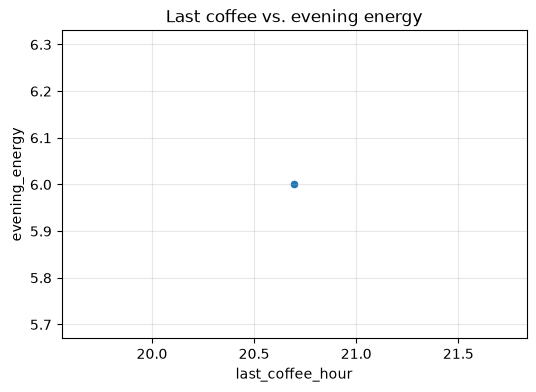

In [6]:
coffee = dt.last_coffee_vs_evening(ex)
ax = coffee.plot.scatter(x='last_coffee_hour', y='evening_energy', figsize=(6, 4),
                         title='Last coffee vs. evening energy')
ax.grid(alpha=0.3)
coffee.dropna().corr().round(2)

## Water vs. energy

       Water  Focus
Water    NaN    NaN
Focus    NaN    NaN


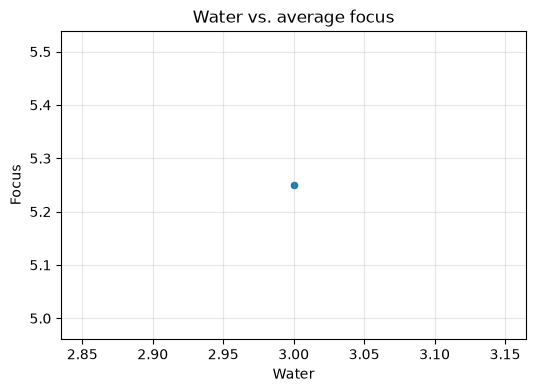

In [10]:
item1 = 'Water'
item2 = 'Focus'
if {item1, item2} <= set(daily.columns):
    ax = daily.plot.scatter(x=item1, y='Focus', figsize=(6, 4), title=f'{item1} vs. average {item2}')
    ax.grid(alpha=0.3)
    print(daily[['Water', 'Focus']].dropna().corr().round(2))

## Medication adherence
`expected_slots` assumes today's reminder times applied every day in the export.

In [8]:
dt.adherence(ex)

,expected_slots,taken,skipped,unanswered,as_needed,taken_rate
medicine,,,,,,
Medicine1,1,1,0,0,2,1.0


## Check-ins

In [9]:
dt.checkin_summary(ex)

status,answered,partial,skipped,missed,pending,response_rate
schedule_name,,,,,,
Afternoon,1,0,0,0,0,1.0
Evening,1,1,0,0,0,1.0
Morning,1,0,0,0,0,1.0
